# 02 - Baseline: HOG features + Support Vector Machine

**Owner:** Faiza Dad - CSC 7333 Group 6

We first consider traditional machine learning methods. A Histogram of Oriented Gradients (HOG) extracts information about a face via the orientation of edges within local cells. Then a Support Vector Machine (SVM) can be trained to distinguish between different expressions.

Pipeline: `48×48 image, HOG, standardize, PCA, SVM`

Hyper-parameters are optimized on the **validation** data. The test split is used only once, at the end. Processing is performed on a CPU and takes around 10 minutes.

In [1]:
import itertools
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

# Folders can be accessed whether the notebook is opened from the root of the repository or from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"
FIG = RESULTS_DIR / "figures"
for folder in (FIG, RESULTS_DIR / "metrics", MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["Neutral", "Happiness", "Surprise", "Sadness", "Anger", "Fear"]
SEED = 42

In [2]:
def load_split(split, size=48):
    # Images and classes for one split. Excludes Disgust and Contempt. As the 224x224 training data exceeds 1 GB,
    # memory mapping is used. Only the selected images are then copied.
    names = np.load(DATA_DIR / f"FER2013{split}_labels.npy")
    images = np.load(DATA_DIR / f"FER2013{split}_{size}_images.npy", mmap_mode="r")
    keep = np.isin(names, CLASSES)
    labels = np.array([CLASSES.index(name) for name in names[keep]])
    return np.ascontiguousarray(images[keep]), labels


def hog_features(images, cell_size, orientations, block_size=2):
    # Each image generates one HOG vector. This is done in parallel on all CPU cores.
    vectors = Parallel(n_jobs=-1, batch_size=500)(
        delayed(hog)(image, orientations=orientations, pixels_per_cell=(cell_size, cell_size),
                     cells_per_block=(block_size, block_size), block_norm="L2-Hys")
        for image in images)
    return np.array(vectors, dtype=np.float32)


def compute_metrics(y_true, y_pred):
    # Accuracy, macro and class level statistics and a confusion matrix. Output is in the format that notebook 06
    # expects.
    labels = range(len(CLASSES))
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1.mean(),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "per_class": {name: {"precision": precision[i], "recall": recall[i], "f1": f1[i], "support": int(support[i])}
                      for i, name in enumerate(CLASSES)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }


X_train, y_train = load_split("Train")
X_valid, y_valid = load_split("Valid")
X_test, y_test = load_split("Test")
print(X_train.shape, X_valid.shape, X_test.shape)

# Test images that are identical to training images (see notebook 01).
train_bytes = {image.tobytes() for image in X_train}
in_train = np.array([image.tobytes() in train_bytes for image in X_test])

(24783, 48, 48) (3140, 48, 48) (3103, 48, 48)


## 1. What HOG sees

For `cell_size × cell_size` pixel cells, HOG forms a histogram of edge orientations. These histograms are normalized within 2×2 cell groups, reducing sensitivity to illumination. Smaller cells retain more information, but produce longer feature vectors.

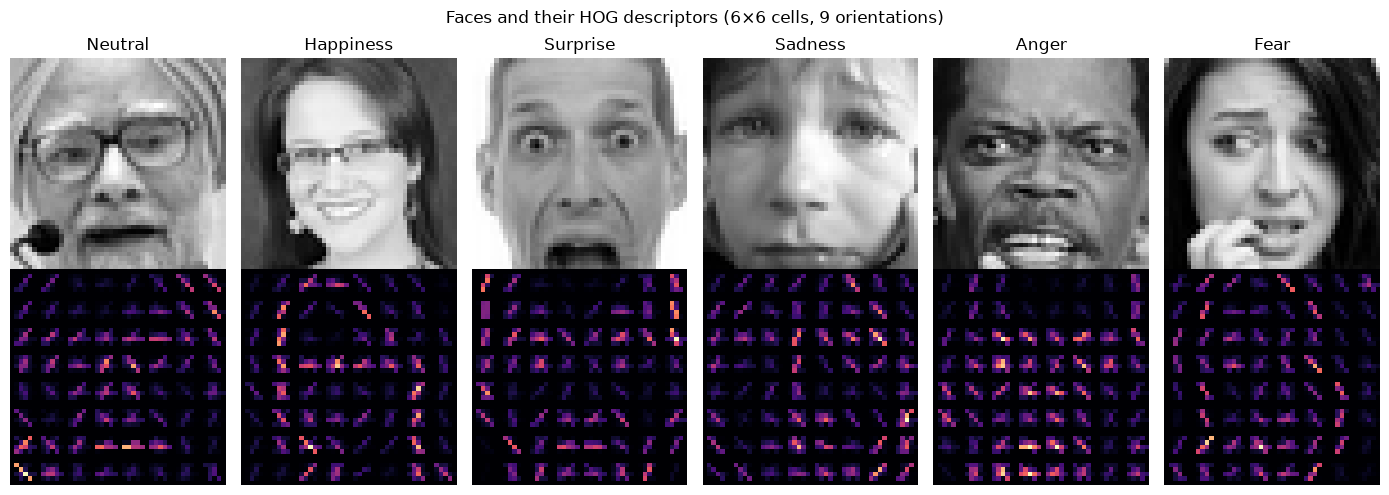

In [3]:
fig, axes = plt.subplots(2, len(CLASSES), figsize=(14, 5))
for c, name in enumerate(CLASSES):
    img = X_train[np.flatnonzero(y_train == c)[0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(6, 6), cells_per_block=(2, 2), visualize=True)
    axes[0, c].imshow(img, cmap="gray")
    axes[1, c].imshow(hog_img, cmap="magma")
    axes[0, c].set_title(name)
    for ax in axes[:, c]:
        ax.axis("off")
plt.suptitle("Faces and their HOG descriptors (6×6 cells, 9 orientations)")
plt.tight_layout()
fig.savefig(FIG / "hog_examples.png", dpi=150)
plt.show()

## 2. Tuning

The RBF SVM has computational complexity of around O(n²) where n is the number of samples. A stratified sample of 8,000 training images is therefore used for hyper-parameter optimization. Macro F1 is calculated on the validation data to determine the optimal hyper-parameters, as accuracy alone would favor the larger classes. The model is then retrained on all 24,783 images with the optimal hyper-parameters.

### 2a. HOG parameters

The SVM (RBF, C = 10) is held constant and different cell sizes and numbers of orientation bins are assessed.

In [4]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=8000, stratify=y_train,
                                      random_state=SEED)


def svm_pipeline(kernel="rbf", C=10.0, gamma="scale", pca_variance=0.95):
    # As with the neural networks, class_weight="balanced" applies inverse class frequency weighting.
    if kernel == "linear":
        svm = LinearSVC(C=C, class_weight="balanced", dual="auto", max_iter=5000, random_state=SEED)
    else:
        svm = SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced", random_state=SEED)
    return make_pipeline(StandardScaler(), PCA(n_components=pca_variance, random_state=SEED), svm)


def score(pipeline, F_fit, y_fit, F_val, y_val):
    pipeline.fit(F_fit, y_fit)
    return f1_score(y_val, pipeline.predict(F_val), average="macro")


hog_grid = list(itertools.product([4, 6, 8], [9, 12]))  # (cell size, orientations)
features = {}
for cell, ori in hog_grid:
    features[(cell, ori)] = (hog_features(X_sub, cell_size=cell, orientations=ori),
                             hog_features(X_valid, cell_size=cell, orientations=ori))

start = time.time()
scores = Parallel(n_jobs=-1)(
    delayed(score)(svm_pipeline(), F_sub, y_sub, F_val, y_valid) for F_sub, F_val in features.values()
)
hog_results = pd.DataFrame(
    [{"cell size": c, "orientations": o, "HOG features": features[(c, o)][0].shape[1], "val macro F1": round(s, 4)}
     for (c, o), s in zip(hog_grid, scores)]
).sort_values("val macro F1", ascending=False)
print(f"{time.time() - start:.0f}s")
hog_results

217s


,cell size,orientations,HOG features,val macro F1
4,8,9,900,0.5783
3,6,12,2352,0.5756
5,8,12,1200,0.5747
2,6,9,1764,0.5708
0,4,9,4356,0.5466
1,4,12,5808,0.5280


In [5]:
best_hog = hog_results.iloc[0]
HOG_PARAMS = {"cell_size": int(best_hog["cell size"]), "orientations": int(best_hog["orientations"]), "block_size": 2}
print("best HOG setting:", HOG_PARAMS)
F_sub, F_val = features[(HOG_PARAMS["cell_size"], HOG_PARAMS["orientations"])]

best HOG setting: {'cell_size': 8, 'orientations': 9, 'block_size': 2}


### 2b. SVM parameters

With the optimal HOG parameters identified, a linear and RBF SVM are compared. The regularization parameter `C` (and for RBF, `gamma`, which controls the reach of each support vector) is then optimized. `gamma` is expressed in relation to scikit-learn's default value of `"scale"`, `1 / (n_features * Var(X))`.

In [6]:
# Calculate the value of gamma="scale" following standardization and PCA so that the grid can be centered on it.
reducer = make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=SEED)).fit(F_sub)
Z = reducer.transform(F_sub)
gamma_scale = 1.0 / (Z.shape[1] * Z.var())
print(f"PCA keeps {Z.shape[1]} of {F_sub.shape[1]} dimensions (95% of the variance), gamma_scale = {gamma_scale:.2e}")

svm_grid = [{"kernel": "linear", "C": C, "gamma": None} for C in (0.001, 0.01, 0.1)]
svm_grid += [{"kernel": "rbf", "C": C, "gamma": g * gamma_scale}
             for C in (1, 3, 10, 30) for g in (0.5, 1, 2)]

start = time.time()
scores = Parallel(n_jobs=-1)(
    delayed(score)(svm_pipeline(p["kernel"], p["C"], p["gamma"] or "scale"), F_sub, y_sub, F_val, y_valid)
    for p in svm_grid
)
svm_results = pd.DataFrame(svm_grid).assign(**{"val macro F1": np.round(scores, 4)})
svm_results["gamma / scale"] = (svm_results["gamma"] / gamma_scale).round(2)
svm_results = svm_results.drop(columns="gamma").sort_values("val macro F1", ascending=False)
print(f"{time.time() - start:.0f}s")
svm_results

PCA keeps 270 of 900 dimensions (95% of the variance), gamma_scale = 1.17e-03


92s


,kernel,C,val macro F1,gamma / scale
9,rbf,10.000,0.5809,0.5
12,rbf,30.000,0.5806,0.5
7,rbf,3.000,0.5791,1.0
13,rbf,30.000,0.5786,1.0
10,rbf,10.000,0.5783,1.0
4,rbf,1.000,0.5700,1.0
6,rbf,3.000,0.5586,0.5
5,rbf,1.000,0.5530,2.0
8,rbf,3.000,0.5495,2.0
11,rbf,10.000,0.5491,2.0


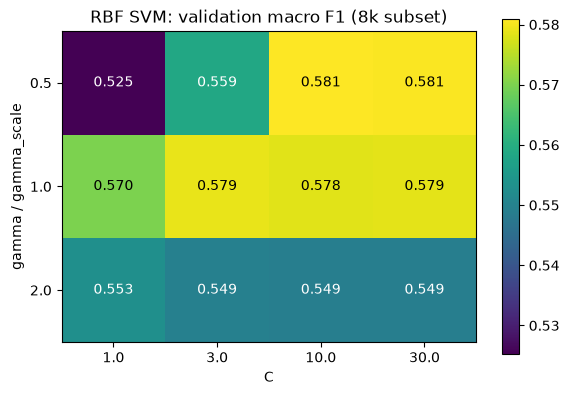

best SVM setting: {'kernel': 'rbf', 'C': 10.0, 'gamma': 0.0005845962441526353}


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
rbf = svm_results[svm_results.kernel == "rbf"].pivot(index="gamma / scale", columns="C", values="val macro F1")
im = ax.imshow(rbf.values, cmap="viridis")
ax.set_xticks(range(len(rbf.columns)), rbf.columns)
ax.set_yticks(range(len(rbf.index)), rbf.index)
ax.set_xlabel("C")
ax.set_ylabel("gamma / gamma_scale")
for (i, j), v in np.ndenumerate(rbf.values):
    ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v < rbf.values.mean() else "black")
ax.set_title("RBF SVM: validation macro F1 (8k subset)")
plt.colorbar(im)
plt.tight_layout()
fig.savefig(FIG / "hog_svm_grid.png", dpi=150)
plt.show()

best_svm = svm_results.iloc[0]
SVM_PARAMS = {"kernel": best_svm["kernel"], "C": float(best_svm["C"]),
              "gamma": None if best_svm["kernel"] == "linear" else float(best_svm["gamma / scale"] * gamma_scale)}
print("best SVM setting:", SVM_PARAMS)

## 3. Final model on the full training set

The complete processing chain (scaler, PCA, SVM) is reapplied to all training images using the optimal parameters. Although the number of PCA components may increase or decrease slightly when applied to all training images (compared to the stratified sample), the variance explained by each is similar. Thus the optimized gamma remains suitable.

In [8]:
start = time.time()
F_train = hog_features(X_train, **HOG_PARAMS)
F_valid = hog_features(X_valid, **HOG_PARAMS)
F_test = hog_features(X_test, **HOG_PARAMS)

model = svm_pipeline(SVM_PARAMS["kernel"], SVM_PARAMS["C"], SVM_PARAMS["gamma"] or "scale")
model.fit(F_train, y_train)
train_time = time.time() - start
print(f"feature extraction + training: {train_time / 60:.1f} min")
print(f"support vectors: {model[-1].n_support_.sum() if hasattr(model[-1], 'n_support_') else 'n/a (linear)'}")

val_f1 = f1_score(y_valid, model.predict(F_valid), average="macro")
print(f"validation macro F1 (full training set): {val_f1:.4f}")

feature extraction + training: 3.4 min
support vectors: 20032


validation macro F1 (full training set): 0.6607


## 4. Test results

In [9]:
start = time.time()
y_pred = model.predict(F_test)
ms_per_image = 1000 * (time.time() - start) / len(y_test)

test_metrics = compute_metrics(y_test, y_pred)
print(f"accuracy {test_metrics['accuracy']:.4f}, macro F1 {test_metrics['macro_f1']:.4f}")
print(pd.DataFrame(test_metrics["per_class"]).T.round(3))

# Same statistics but for test images not also present in the training data.
clean_metrics = compute_metrics(y_test[~in_train], y_pred[~in_train])
print(f"\nclean test subset ({(~in_train).sum()} images): accuracy {clean_metrics['accuracy']:.4f}, "
      f"macro F1 {clean_metrics['macro_f1']:.4f}")

accuracy  0.7083
macro F1  0.6313
class        prec recall     f1      n
Neutral     0.691  0.769  0.728   1081
Happiness   0.779  0.820  0.799    891
Surprise    0.764  0.730  0.747    400
Sadness     0.520  0.438  0.475    384
Anger       0.696  0.568  0.625    266
Fear        0.625  0.309  0.413     81

clean test subset (2874 images): accuracy 0.6924, macro F1 0.5960


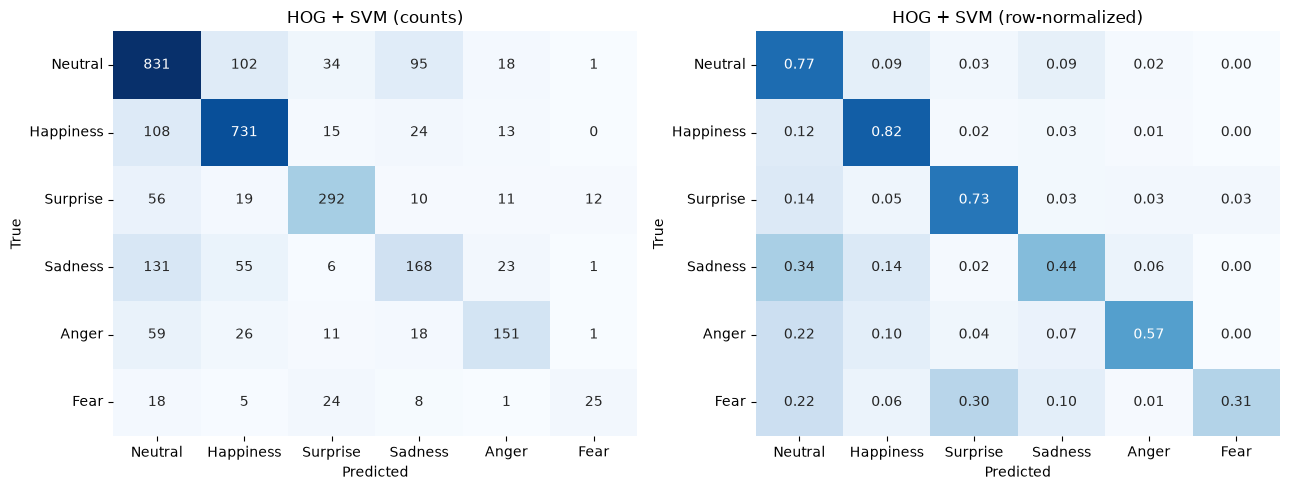

In [10]:
cm = np.array(test_metrics["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
# Each row is divided by its sum. Diagonal entries then indicate the recall for each class.
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[0].set_title("HOG + SVM (counts)")
axes[1].set_title("HOG + SVM (row-normalized)")
for ax in axes:
    ax.set(xlabel="Predicted", ylabel="True")
plt.tight_layout()
fig.savefig(FIG / "hog_svm_confusion.png", dpi=150)
plt.show()

In [11]:
joblib.dump({"pipeline": model, "hog_params": HOG_PARAMS, "classes": CLASSES}, MODELS_DIR / "hog_svm.joblib")

metrics = {
    "model": "hog_svm",
    "test": test_metrics,
    "test_clean": clean_metrics,
    "val_macro_f1": val_f1,
    "hyperparameters": {**HOG_PARAMS, **SVM_PARAMS, "pca_variance": 0.95,
                        "pca_components": int(model[1].n_components_)},
    "tuning": {"hog": hog_results.to_dict("records"), "svm": svm_results.to_dict("records")},
    "train_time_sec": round(train_time, 1),
    "inference_ms_per_image": round(ms_per_image, 3),
}
(RESULTS_DIR / "metrics" / "hog_svm.json").write_text(json.dumps(metrics, indent=2))

saved /home/luizsusin/ferplus-project/results/metrics/hog_svm.json


## 5. Observations

- Optimal validation performance was achieved with relatively coarse HOG cells (8×8 pixels, 900 features). The finest 4×4 pixel cells (up to 5,808 features) performed poorest. With only 8,000 images available for hyper-parameter optimization, the extra detail mostly adds noise.
- As shown, the RBF kernel outperforms the linear SVM (macro F1 ≈ 0.58 compared to 0.44 on the stratified sample). Therefore, the classes are not linearly separable in HOG feature space. Validation macro F1 was improved by re-training on the complete training data to 0.66 from 0.58.
- Expressions most successfully recognized are Happiness, Surprise and Neutral. Both Happiness and Surprise exhibit highly characteristic edge profiles (mouth open and raised eyebrows).
- Fear and Sadness are most challenging. 30% of Fear images are misclassified as Surprise (both share wide eyes and an open mouth). Similarly, 34% of Sadness images are labeled as Neutral. Despite applying class weighting, many errors are attributed to Neutral.
- On the *clean* test subset (with no images that also appear in Train), macro F1 falls to 0.60 from 0.63.
- Neural networks must outperform these results (see notebook 06).